# Section 5.2: COVID-19 Vaccine Conjoint Analysis (Wang et al., 2026 Benchmark)

This notebook dynamically discovers all collected generative LLM and decision-model choice datasets on the Kreps et al. (2020) / Wang et al. (2026) COVID-19 vaccine conjoint benchmark, estimates multinomial logit (MNL) part-worth utilities via maximum likelihood, prints the formatted Markdown tables (`#tbl-wang-mnl` and `#apptbl-wang-coefs`), and saves the publication figures (`wang_mnl_random.pdf`, `wang_mnl_persona.pdf`, and `wang_mnl_coefs.pdf`) directly in `code/analysis/wang2026/`.

## 1. Setup & Ground-Truth Human MNL Estimation

In [1]:
import importlib
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wang_mnl

importlib.reload(wang_mnl)
from wang_mnl import (
    build_wang_coef_table,
    build_wang_summary_table,
    encode_design_matrix,
    evaluate_wang_metrics,
    fit_mnl_mle,
    load_all_model_regressions,
    load_covid_conjoint,
    pair_choice_sets,
    plot_wang_coefficients,
    plot_wang_error_comparison,
)

OUT_DIR = Path(".").resolve()
DATA_PATH = Path("../../data/covid/dataverse_files/Kreps_etal_vax_replication_data.dta")
raw_df = load_covid_conjoint(DATA_PATH)
df_A, df_B, y_human_A, y_human_B, y_human_C = pair_choice_sets(raw_df)
X_A = encode_design_matrix(df_A)
X_B = encode_design_matrix(df_B)

print(f"Loaded {len(df_A):,} paired choice sets across {df_A['respondent'].nunique():,} respondents (d={X_A.shape[1]} features)")

# Fit full-sample human ground-truth MNL regression (beta*, N = 9,855 pairs)
human_mnl_df = fit_mnl_mle(X_A, X_B, y_human_A, y_human_B, y_human_C)
beta_star = human_mnl_df["beta"].copy()

# Subsample the 200 respondents (1,000 choice sets, seed=42) and fit Human Subsample Baseline MNL (beta_sub)
N_LLM_RESPONDENTS = 200
SUBSAMPLE_SEED = 42

all_respondents = np.sort(df_A["respondent"].unique())
rng = np.random.default_rng(SUBSAMPLE_SEED)
sampled_respondents = np.sort(rng.choice(all_respondents, size=N_LLM_RESPONDENTS, replace=False))

sub_mask = df_A["respondent"].isin(sampled_respondents).to_numpy()
sub_df_A = df_A.loc[sub_mask].reset_index(drop=True)
sub_df_B = df_B.loc[sub_mask].reset_index(drop=True)
X_A_sub = X_A[sub_mask]
X_B_sub = X_B[sub_mask]
y_human_A_sub = y_human_A[sub_mask]
y_human_B_sub = y_human_B[sub_mask]
y_human_C_sub = y_human_C[sub_mask]

subsample_keys = [(int(r["respondent"]), int(r["pair_id"])) for r in sub_df_A[["respondent", "pair_id"]].to_dict("records")]

human_sub_mnl_df = fit_mnl_mle(X_A_sub, X_B_sub, y_human_A_sub, y_human_B_sub, y_human_C_sub)
beta_human_sub = human_sub_mnl_df["beta"].copy()
human_sub_metrics = evaluate_wang_metrics(beta_human_sub, beta_star)

print(
    f"Human Subsample Baseline (n={len(sub_df_A):,} pairs) vs. Full Human (beta*): "
    f"MAPE = {human_sub_metrics['MAPE (%)']:.2f}%, MSE = {human_sub_metrics['MSE']:.4f}"
)

Loaded 9,855 paired choice sets across 1,971 respondents (d=11 features)
Human Subsample Baseline (n=1,000 pairs) vs. Full Human (beta*): MAPE = 22.08%, MSE = 0.0065


## 2. Dynamic Discovery of Model Predictions & MNL Estimation

In [2]:
model_mnl_dfs = load_all_model_regressions(
    X_A_sub,
    X_B_sub,
    subsample_keys,
    gemini_data_dir="../../proprietary-llms/gemini/data",
    kev_data_dir="data",
)
print(f"Dynamically loaded and fitted {len(model_mnl_dfs)} model datasets:")
for name in model_mnl_dfs:
    print(" -", name)

human_sub_key = f"Human Subsample Baseline (n={len(sub_df_A)})"
estimators_beta = {
    human_sub_key: beta_human_sub,
    **{name: df_m["beta"] for name, df_m in model_mnl_dfs.items()},
}

comparison_rows = {}
for name, b_hat in estimators_beta.items():
    vs_full = evaluate_wang_metrics(b_hat, beta_star)
    vs_sub = evaluate_wang_metrics(b_hat, beta_human_sub)
    comparison_rows[name] = {
        "MAPE vs. Full Human (%)": vs_full["MAPE (%)"],
        "MSE vs. Full Human": vs_full["MSE"],
        "MAPE vs. Human Subsample (%)": vs_sub["MAPE (%)"],
        "MSE vs. Human Subsample": vs_sub["MSE"],
    }

comparison_metrics_df = pd.DataFrame(comparison_rows).T.sort_values("MSE vs. Full Human", ascending=True)

[WARNING] gemini-4-argon_HIGH_random.jsonl: dropped 16/1000 non-A/B/C refusal responses (fitting on valid n=984; first 3 refusal keys: [(112, 5), (530, 2), (581, 5)])
Dynamically loaded and fitted 12 model datasets:
 - gemini-3.5-flash-lite (HIGH, Respondent Persona, n=1000)
 - gemini-3.5-flash-lite (HIGH, Random Persona, n=1000)
 - gemini-3.5-flash-lite (MINIMAL, Respondent Persona, n=1000)
 - gemini-3.5-flash-lite (MINIMAL, Random Persona, n=1000)
 - gemini-4-argon (HIGH, Respondent Persona, n=1000)
 - gemini-4-argon (HIGH, Random Persona, n=984)
 - gemini-4-argon (LOW, Respondent Persona, n=1000)
 - gemini-4-argon (LOW, Random Persona, n=1000)
 - jaredpalmer/kev-9b (Respondent Persona, n=1000)
 - jaredpalmer/kev-9b (Random Persona, n=1000)
 - kev-9b-resp-issp+twin2k-grouped-newvalid/best (Respondent Persona, n=1000)
 - kev-9b-resp-issp+twin2k-grouped-newvalid/best (Random Persona, n=1000)


## 3. Main-Text Table: MNL Part-Worth Recovery (`#tbl-wang-mnl`)

In [3]:
tbl_wang_df = build_wang_summary_table(comparison_metrics_df, human_sub_key=human_sub_key)
display(tbl_wang_df)

print("\n--- Markdown for #tbl-wang-mnl ---\n")
colalign = ("left",) + ("right",) * (len(tbl_wang_df.columns) - 1)
print(tbl_wang_df.to_markdown(index=False, disable_numparse=True, colalign=colalign))
print("\n: Multinomial logit (MNL) part-worth parameter recovery on the COVID-19 vaccine conjoint benchmark (Kreps et al., 2020; Wang et al., 2026) across the 200-respondent evaluation subsample (n = 1,000 choice sets, d = 11 attribute levels), evaluated against the full-sample human benchmark (N = 1,971 respondents, 9,855 choice sets) and the same 200-respondent human subsample. {#tbl-wang-mnl}")

,Estimator,Random persona MAPE (%),Random persona MSE,Respondent persona MAPE (%),Respondent persona MSE
0,"Human subsample (n = 1,000)",—,—,22.1%,0.0065
1,Kev 9B FT,51.8%,0.0205,56.6%,0.0239
2,Kev 9B (base),110.8%,0.0932,87.4%,0.0982
3,Gemini 3.5 Flash-Lite (minimal),531.7%,3.2073,203.6%,0.5925
4,Gemini 3.5 Flash-Lite (high),998.2%,14.4555,335.8%,1.1984
5,Gemini 4 Argon (low),1394.3%,23.3998,376.7%,1.7637
6,Gemini 4 Argon (high) (random n = 984),1507.7%,26.2179,395.1%,2.1687



--- Markdown for #tbl-wang-mnl ---

| Estimator                              |   Random persona MAPE (%) |   Random persona MSE |   Respondent persona MAPE (%) |   Respondent persona MSE |
|:---------------------------------------|--------------------------:|---------------------:|------------------------------:|-------------------------:|
| Human subsample (n = 1,000)            |                         — |                    — |                         22.1% |                   0.0065 |
| Kev 9B FT                              |                     51.8% |               0.0205 |                         56.6% |                   0.0239 |
| Kev 9B (base)                          |                    110.8% |               0.0932 |                         87.4% |                   0.0982 |
| Gemini 3.5 Flash-Lite (minimal)        |                    531.7% |               3.2073 |                        203.6% |                   0.5925 |
| Gemini 3.5 Flash-Lite (high)           |   

## 4. Main-Text Figures: Random Persona & Respondent Persona MNL Recovery (`wang_mnl_random.pdf`, `wang_mnl_persona.pdf`)

Saved /home/dw/github/decision-models-finetuning/code/analysis/wang2026/wang_mnl_random.pdf


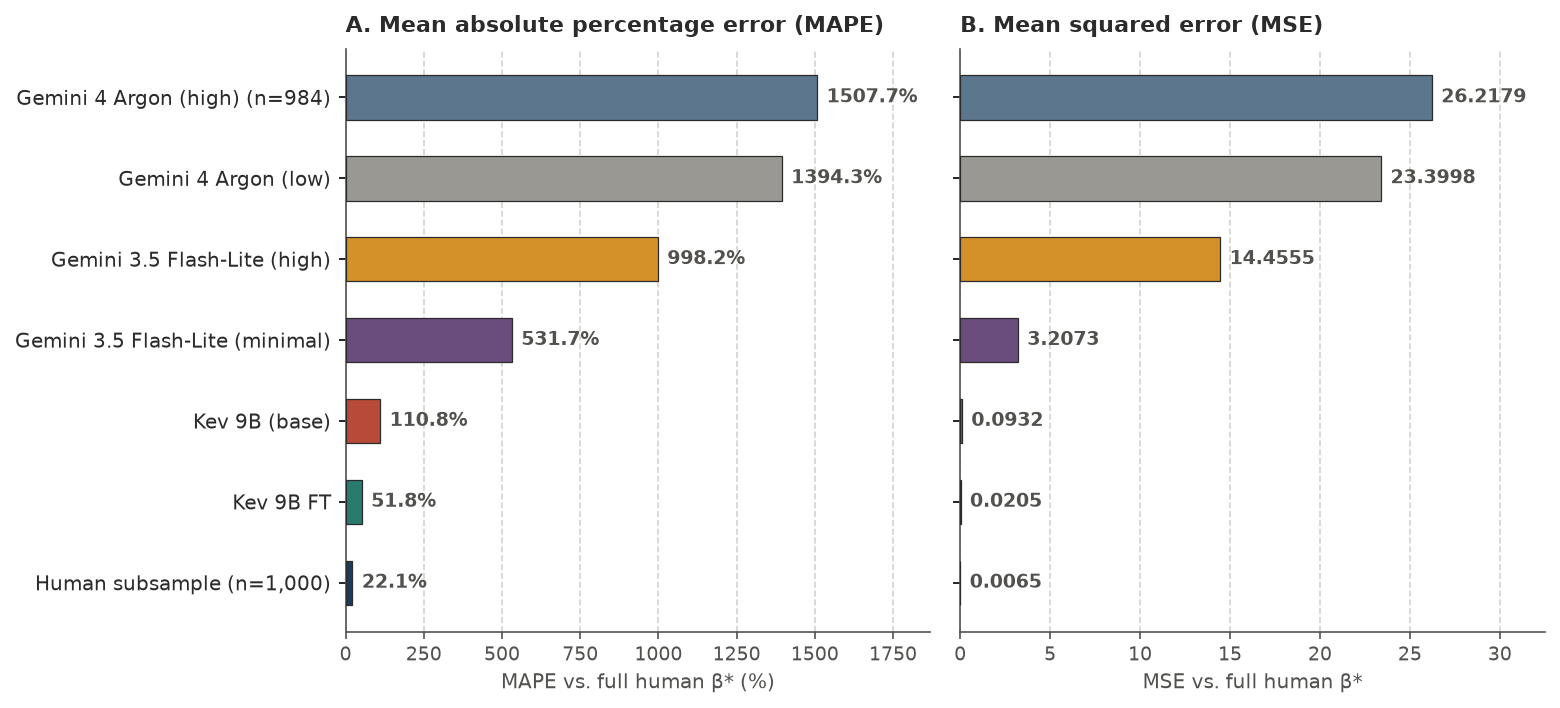

In [4]:
fig_random = plot_wang_error_comparison(
    comparison_metrics_df,
    palette="nature",
    persona_filter="Random Persona",
    sort_by="MSE vs. Full Human",
)
fig_random.savefig(OUT_DIR / "wang_mnl_random.pdf", bbox_inches="tight")
fig_random.savefig(OUT_DIR / "wang_mnl_random.png", dpi=300, bbox_inches="tight")
print(f"Saved {OUT_DIR / 'wang_mnl_random.pdf'}")
plt.show()

Saved /home/dw/github/decision-models-finetuning/code/analysis/wang2026/wang_mnl_persona.pdf


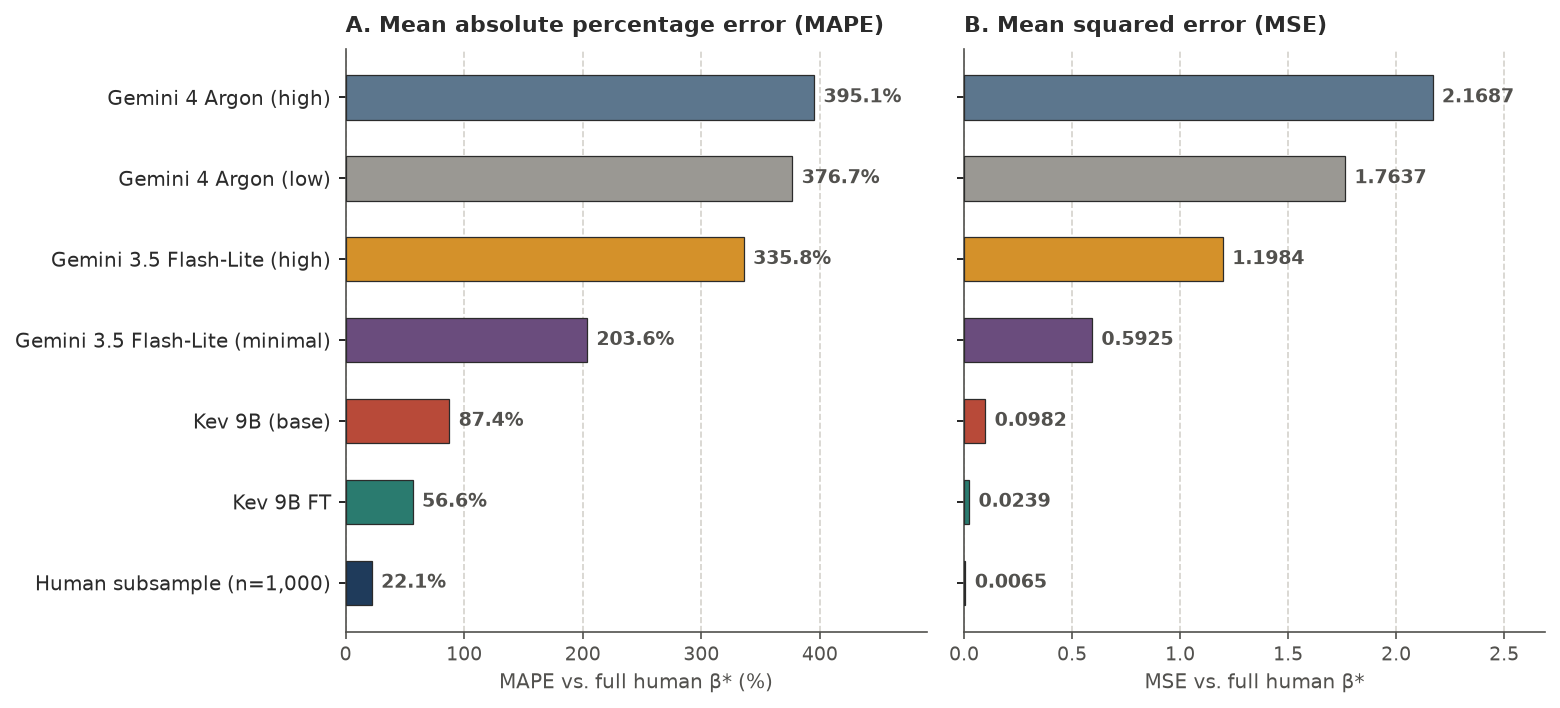

In [5]:
fig_persona = plot_wang_error_comparison(
    comparison_metrics_df,
    palette="nature",
    persona_filter="Respondent Persona",
    sort_by="MSE vs. Full Human",
)
fig_persona.savefig(OUT_DIR / "wang_mnl_persona.pdf", bbox_inches="tight")
fig_persona.savefig(OUT_DIR / "wang_mnl_persona.png", dpi=300, bbox_inches="tight")
print(f"Saved {OUT_DIR / 'wang_mnl_persona.pdf'}")
plt.show()

## 5. Main-Text Figure: Estimated Part-Worth Coefficients Across Vaccine Attributes (`wang_mnl_coefs.pdf`)

Saved /home/dw/github/decision-models-finetuning/code/analysis/wang2026/wang_mnl_coefs.pdf


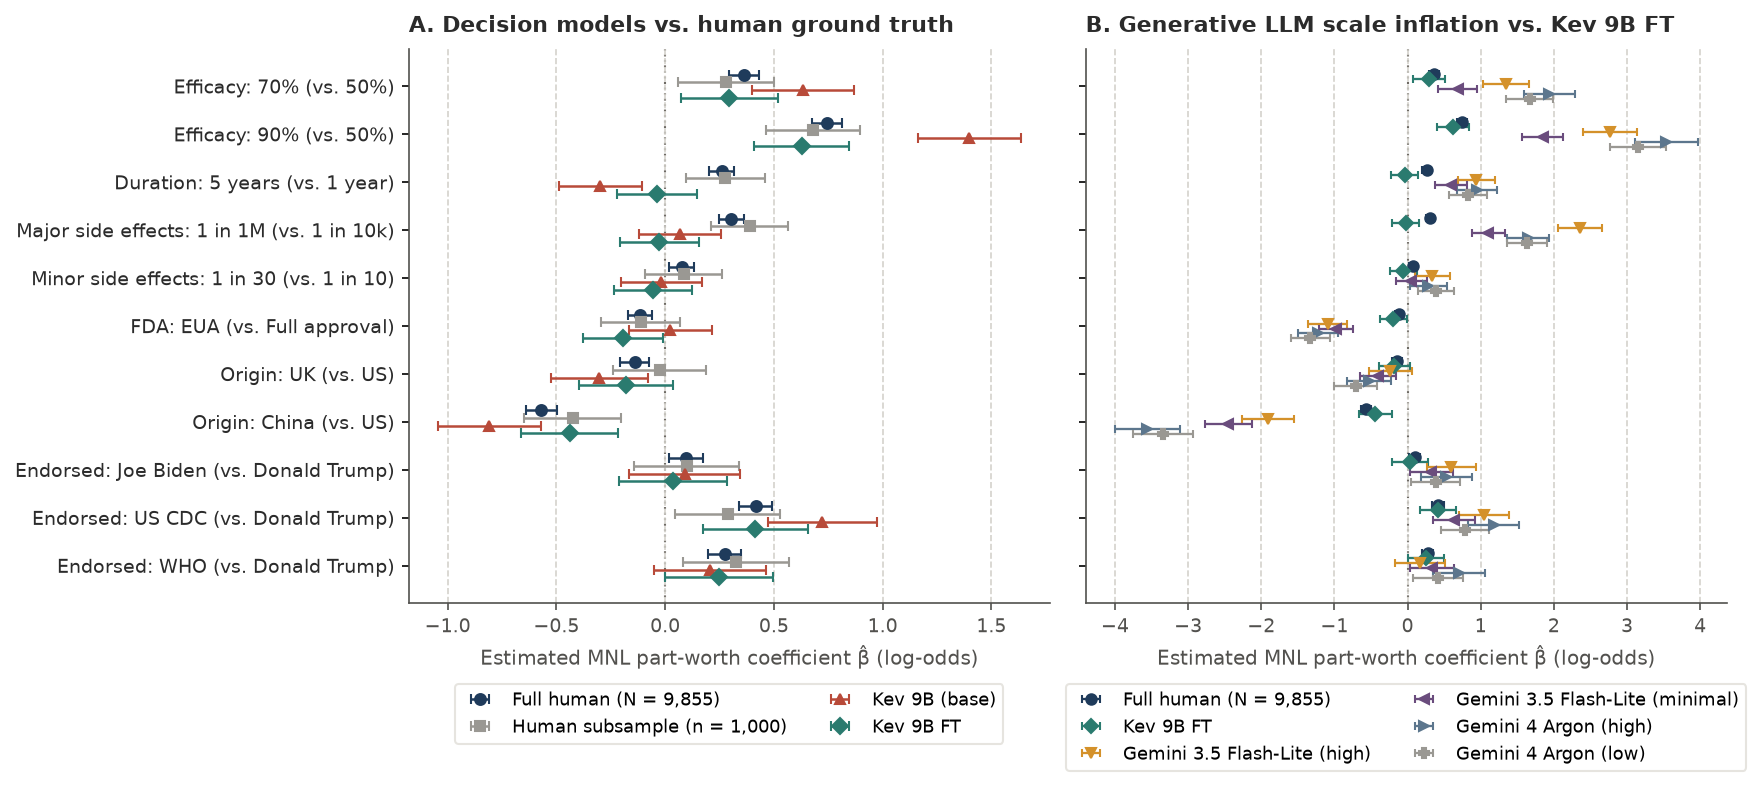

In [6]:
fig_coefs = plot_wang_coefficients(
    human_mnl_df,
    human_sub_mnl_df,
    model_mnl_dfs,
    palette="nature",
    persona_mode="Respondent Persona",
)
fig_coefs.savefig(OUT_DIR / "wang_mnl_coefs.pdf", bbox_inches="tight")
fig_coefs.savefig(OUT_DIR / "wang_mnl_coefs.png", dpi=300, bbox_inches="tight")
print(f"Saved {OUT_DIR / 'wang_mnl_coefs.pdf'}")
plt.show()

## 6. Web Appendix Table: Attribute-Level MNL Part-Worth Estimates (`#apptbl-wang-coefs`)

In [7]:
apptbl_coefs_df = build_wang_coef_table(
    human_mnl_df,
    human_sub_mnl_df,
    model_mnl_dfs,
    persona_mode="Respondent Persona",
)
display(apptbl_coefs_df)

print("\n--- Markdown for #apptbl-wang-coefs ---\n")
colalign_coef = ("left",) + ("right",) * (len(apptbl_coefs_df.columns) - 1)
print('::: {#apptbl-wang-coefs size="scriptsize"}\n')
print(apptbl_coefs_df.to_markdown(index=False, disable_numparse=True, colalign=colalign_coef))
print("\nEstimated multinomial logit (MNL) part-worth coefficients and asymptotic standard errors (in parentheses) across the 11 COVID-19 vaccine attribute levels under respondent-persona conditioning.\n\n:::")

,Vaccine attribute level,"Full human (N = 9,855)","Human subsample (n = 1,000)",Kev 9B FT,Kev 9B (base),Gemini 3.5 Flash-Lite (high),Gemini 3.5 Flash-Lite (minimal),Gemini 4 Argon (high),Gemini 4 Argon (low)
0,Efficacy: 70% (vs. 50%),+0.361 (0.035),+0.280 (0.112),+0.296 (0.113),+0.634 (0.119),+1.344 (0.158),+0.688 (0.135),+1.940 (0.176),+1.671 (0.163)
1,Efficacy: 90% (vs. 50%),+0.746 (0.035),+0.679 (0.110),+0.627 (0.112),+1.399 (0.120),+2.764 (0.188),+1.846 (0.145),+3.538 (0.218),+3.148 (0.196)
2,Duration: 5 years (vs. 1 year),+0.261 (0.029),+0.277 (0.092),-0.037 (0.093),-0.298 (0.098),+0.940 (0.131),+0.592 (0.114),+0.948 (0.140),+0.830 (0.133)
3,"Major side effects: 1 in 1,000,000 (vs. 1 in 1...",+0.304 (0.029),+0.389 (0.091),-0.027 (0.092),+0.068 (0.095),+2.353 (0.154),+1.103 (0.114),+1.647 (0.146),+1.634 (0.140)
4,Minor side effects: 1 in 30 (vs. 1 in 10),+0.076 (0.029),+0.085 (0.090),-0.056 (0.092),-0.018 (0.095),+0.341 (0.124),+0.051 (0.109),+0.282 (0.128),+0.389 (0.124)
5,FDA: Emergency Use Authorization (vs. Full app...,-0.115 (0.029),-0.113 (0.092),-0.195 (0.093),+0.024 (0.096),-1.089 (0.136),-0.978 (0.115),-1.223 (0.141),-1.329 (0.137)
6,Origin: United Kingdom (vs. United States),-0.140 (0.035),-0.026 (0.109),-0.180 (0.110),-0.303 (0.114),-0.234 (0.151),-0.402 (0.127),-0.527 (0.157),-0.710 (0.151)
7,Origin: China (vs. United States),-0.570 (0.036),-0.425 (0.113),-0.439 (0.113),-0.808 (0.121),-1.908 (0.179),-2.449 (0.164),-3.556 (0.227),-3.341 (0.210)
8,Endorsed: Joe Biden (vs. Donald Trump),+0.095 (0.040),+0.100 (0.123),+0.036 (0.126),+0.090 (0.130),+0.600 (0.171),+0.325 (0.148),+0.531 (0.178),+0.385 (0.170)
9,Endorsed: US CDC (vs. Donald Trump),+0.416 (0.039),+0.287 (0.123),+0.415 (0.124),+0.722 (0.128),+1.045 (0.172),+0.635 (0.148),+1.175 (0.179),+0.784 (0.169)



--- Markdown for #apptbl-wang-coefs ---

::: {#apptbl-wang-coefs size="scriptsize"}

| Vaccine attribute level                              |   Full human (N = 9,855) |   Human subsample (n = 1,000) |      Kev 9B FT |   Kev 9B (base) |   Gemini 3.5 Flash-Lite (high) |   Gemini 3.5 Flash-Lite (minimal) |   Gemini 4 Argon (high) |   Gemini 4 Argon (low) |
|:-----------------------------------------------------|-------------------------:|------------------------------:|---------------:|----------------:|-------------------------------:|----------------------------------:|------------------------:|-----------------------:|
| Efficacy: 70% (vs. 50%)                              |           +0.361 (0.035) |                +0.280 (0.112) | +0.296 (0.113) |  +0.634 (0.119) |                 +1.344 (0.158) |                    +0.688 (0.135) |          +1.940 (0.176) |         +1.671 (0.163) |
| Efficacy: 90% (vs. 50%)                              |           +0.746 (0.035) |                +0